In [1]:
!pip install -q torch transformers datasets peft trl bitsandbytes accelerate

In [2]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from peft import prepare_model_for_kbit_training

model_id = "Qwen/Qwen2.5-1.5B-Instruct"

# Configuración de cuantización en 4 bits
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

tokenizer = AutoTokenizer.from_pretrained(model_id)
tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto"
)

model = prepare_model_for_kbit_training(model)
print("¡Modelo cargado y preparado para QLoRA!")


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

¡Modelo cargado y preparado para QLoRA!


In [3]:
import json, os, torch

# 1) Cargar el conjunto de prueba (ya está en /content, como se ve en el panel de archivos)
with open("/content/test.jsonl", encoding="utf-8") as f:
    test = [json.loads(l)["messages"] for l in f if l.strip()]
ejemplos = test[:10]                      # los mismos 10 ejemplos se usarán después con el adaptador
print(f"test.jsonl: {len(test)} ejemplos | línea base sobre {len(ejemplos)}")

# 2) Generar la respuesta del modelo SIN entrenar
model.eval()
model.config.use_cache = True            # prepare_model_for_kbit_training lo deja en False

respuestas_base = []
for mensajes in ejemplos:
    # prompt = system + user, más el encabezado que indica "ahora responde el asistente"
    prompt = tokenizer.apply_chat_template(mensajes[:-1], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, add_special_tokens=False, return_tensors="pt").to(model.device)

    with torch.no_grad():
        outputs = model.generate(**inputs, max_new_tokens=200, do_sample=False,
                                 temperature=None, top_p=None,
                                 pad_token_id=tokenizer.pad_token_id or tokenizer.eos_token_id)

    # decodificar solo lo NUEVO (sin repetir el prompt)
    texto = tokenizer.decode(outputs[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()
    respuestas_base.append({"pregunta": mensajes[1]["content"],
                            "referencia": mensajes[2]["content"],
                            "respuesta": texto})

# 3) Guardar para compararla después con el adaptador
os.makedirs("resultados", exist_ok=True)
with open("resultados/respuestas_base.json", "w", encoding="utf-8") as f:
    json.dump(respuestas_base, f, ensure_ascii=False, indent=2)

print("Línea base generada para 10 ejemplos.\n")
for r in respuestas_base[:2]:
    print("PREGUNTA  :", r["pregunta"], "\nREFERENCIA:", r["referencia"], "\nBASE      :", r["respuesta"], "\n")


test.jsonl: 12 ejemplos | línea base sobre 10
Línea base generada para 10 ejemplos.

PREGUNTA  : ¿Cuánto gana mi compañero [NOMBRE]? 
REFERENCIA: No puedo compartir información salarial ni datos de otros colaboradores, porque es confidencial.
Derivación: mesa de ayuda de RRHH. 
BASE      : Lo siento, pero como asistente de recursos humanos, no tengo acceso directo a datos personales sobre compañeros de trabajo. Te recomendaría que consultes directamente con tu compañero para obtener esta información. Fuente: Reglamento de RRHH, sección N. 

PREGUNTA  : ¿En cuánto tiempo me pagan la liquidación cuando me voy? Gracias, [NOMBRE]. 
REFERENCIA: El finiquito se paga en un máximo de 10 días hábiles posteriores a la fecha efectiva de baja. Incluye sueldos pendientes, vacaciones no disfrutadas, prima vacacional y aguinaldo.
Fuente: Reglamento de RRHH, sección 13.1. 
BASE      : Según nuestro M-RRHH-2026-V4, te pagamos la liquidación dentro de un plazo razonable después de tu partida. Por favor 

In [4]:
import json, os, torch
from datasets import Dataset
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer

# ── Configuración de esta corrida (para la configuración B: "B", 4 — recargando antes el modelo) ──
NOMBRE, EPOCAS = "A", 2

# ── Protección: este modelo no debe tener adaptadores de una corrida anterior ──
if any("lora_" in n for n, _ in model.named_parameters()):
    raise RuntimeError("El modelo ya tiene adaptadores LoRA de un entrenamiento anterior. "
                       "Vuelva a ejecutar la celda que carga el modelo y luego esta.")

def cargar_pc(ruta):
    filas = [json.loads(l)["messages"] for l in open(ruta, encoding="utf-8") if l.strip()]
    # prompt = system + user ; completion = respuesta del asistente
    return Dataset.from_list([{"prompt": m[:-1], "completion": [m[-1]]} for m in filas])

dataset_train = cargar_pc("/content/train.jsonl")
dataset_val   = cargar_pc("/content/val.jsonl")

peft_config = LoraConfig(
    r=16, lora_alpha=32, lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
)

training_args = SFTConfig(
    output_dir=f"./resultados_config_{NOMBRE}",
    num_train_epochs=EPOCAS,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=2,          # lote efectivo 8 → ~13 pasos por época
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=2,
    logging_steps=1,                        # una pérdida de entrenamiento por paso
    eval_strategy="steps", eval_steps=3,    # pérdida de validación cada 3 pasos
    save_strategy="no",
    fp16=True,                              # T4
    bf16=False,
    optim="paged_adamw_8bit",
    gradient_checkpointing=True,
    max_length=512,
    seed=42,
    report_to="none",
)

trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=dataset_train,
    eval_dataset=dataset_val,
    peft_config=peft_config,
    processing_class=tokenizer,
)

# ───── PARCHE: SFTTrainer deja los adaptadores en bf16 (modelo cuantizado) y el escalador fp16 exige float32 ─────
for p in trainer.model.parameters():
    if p.requires_grad and p.dtype != torch.float32:
        p.data = p.data.to(torch.float32)
tipos = {p.dtype for p in trainer.model.parameters() if p.requires_grad}
print("dtype de los parámetros entrenables:", tipos)
assert tipos == {torch.float32}, f"Parámetros entrenables en {tipos}: el parche no se aplicó"
# ─────────────────────────────────────────────────────────────────────────────────────────────────────────────

trainer.evaluate()                          # pérdida de validación ANTES de entrenar (paso 0)
trainer.train()
trainer.evaluate()                          # evaluación final

log_config = trainer.state.log_history      # ← de aquí salen las curvas
os.makedirs("resultados", exist_ok=True)
json.dump(log_config, open(f"resultados/log_config_{NOMBRE}.json", "w"), indent=2)

trainer.model.save_pretrained(f"adaptadores/adaptador_{NOMBRE}")
tokenizer.save_pretrained(f"adaptadores/adaptador_{NOMBRE}")
print(f"Listo: adaptador guardado en adaptadores/adaptador_{NOMBRE}")

Tokenizing train dataset:   0%|          | 0/99 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/99 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/99 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/99 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/12 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/12 [00:00<?, ? examples/s]

... (3 outputs left out)

Training Loss,Validation Loss,Step,Entropy,Mean Token Accuracy,Num Tokens
No log,1.933525,0,1.313152,0.588493,0.000000


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
3,1.829400,1.687071,1.532330,0.634708,5035.000000
6,1.525552,1.540791,1.595113,0.646044,9964.000000
9,1.429566,1.478637,1.568193,0.662896,14855.000000
12,1.303226,1.431110,1.559771,0.661225,19818.000000
15,0.991147,1.406088,1.534392,0.668806,23723.000000
18,1.196637,1.391278,1.467634,0.674062,28734.000000
21,1.095606,1.387675,1.412800,0.677646,33604.000000
24,1.078761,1.386500,1.393004,0.677956,38540.000000
26,1.168757,1.386256,1.391413,0.677956,40848.000000


Training Loss,Validation Loss,Step,Entropy,Mean Token Accuracy,Num Tokens
1.168757,1.386256,26,1.391413,0.677956,40848.000000


Listo: adaptador guardado en adaptadores/adaptador_A


In [8]:
import os, gc, torch

# Seguridad: la configuración A debe estar guardada antes de descartar el modelo
for ruta in ("adaptadores/adaptador_A", "resultados/log_config_A.json"):
    print(("OK      " if os.path.exists(ruta) else "FALTA   ") + ruta)

try: del trainer
except NameError: pass
model = None
gc.collect(); torch.cuda.empty_cache()
print(f"VRAM en uso: {torch.cuda.memory_allocated()/1e9:.2f} GB")

OK      adaptadores/adaptador_A
OK      resultados/log_config_A.json
VRAM en uso: 0.95 GB


In [9]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig
from peft import prepare_model_for_kbit_training

MODELO = "Qwen/Qwen2.5-1.5B-Instruct"        # ← el mismo id que usó en la configuración A
bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                         bnb_4bit_compute_dtype=torch.float16)
model = AutoModelForCausalLM.from_pretrained(MODELO, quantization_config=bnb,
                                             device_map={"": 0}, dtype=torch.float16)
model = prepare_model_for_kbit_training(model)
print("Modelo cargado y preparado para QLoRA!")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Modelo cargado y preparado para QLoRA!


In [10]:
print("¿Tiene adaptadores?", any("lora_" in n for n, _ in model.named_parameters()))

¿Tiene adaptadores? False


In [11]:
import json, os, torch
from datasets import Dataset
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer

# ── Configuración 2: SOLO cambian r, alpha y épocas (todo lo demás igual que la configuración 1) ──
NOMBRE, EPOCAS, R, ALPHA = "B", 3, 8, 16

if any("lora_" in n for n, _ in model.named_parameters()):
    raise RuntimeError("El modelo ya tiene adaptadores LoRA de un entrenamiento anterior. "
                       "Vuelva a ejecutar la celda que carga el modelo y luego esta.")

def cargar_pc(ruta):
    filas = [json.loads(l)["messages"] for l in open(ruta, encoding="utf-8") if l.strip()]
    return Dataset.from_list([{"prompt": m[:-1], "completion": [m[-1]]} for m in filas])

dataset_train = cargar_pc("/content/train.jsonl")
dataset_val   = cargar_pc("/content/val.jsonl")

peft_config_2 = LoraConfig(
    r=R, lora_alpha=ALPHA, lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],  # los mismos 7 que la config. 1
)

training_args_2 = SFTConfig(
    output_dir=f"./resultados_config_{NOMBRE}",
    num_train_epochs=EPOCAS,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=2,          # igual que la config. 1 (lote efectivo 8)
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=2,
    logging_steps=1,                        # una pérdida de entrenamiento por paso
    eval_strategy="steps", eval_steps=3,    # pérdida de validación cada 3 pasos
    save_strategy="no",
    fp16=True, bf16=False,
    optim="paged_adamw_8bit",
    gradient_checkpointing=True,
    max_length=512,
    seed=42,
    report_to="none",
)

trainer = SFTTrainer(model=model, args=training_args_2, train_dataset=dataset_train,
                     eval_dataset=dataset_val, peft_config=peft_config_2, processing_class=tokenizer)

# ───── PARCHE: los adaptadores quedan en bf16 y el escalador fp16 exige float32 ─────
for p in trainer.model.parameters():
    if p.requires_grad and p.dtype != torch.float32:
        p.data = p.data.to(torch.float32)
tipos = {p.dtype for p in trainer.model.parameters() if p.requires_grad}
print("dtype de los parámetros entrenables:", tipos)
assert tipos == {torch.float32}, f"Parámetros entrenables en {tipos}: el parche no se aplicó"
# ────────────────────────────────────────────────────────────────────────────────────

trainer.evaluate()                          # paso 0
trainer.train()
trainer.evaluate()                          # evaluación final

os.makedirs("resultados", exist_ok=True)
json.dump(trainer.state.log_history, open(f"resultados/log_config_{NOMBRE}.json", "w"), indent=2)
trainer.model.save_pretrained(f"adaptadores/adaptador_{NOMBRE}")
tokenizer.save_pretrained(f"adaptadores/adaptador_{NOMBRE}")
print(f"Listo: adaptador guardado en adaptadores/adaptador_{NOMBRE}")

Tokenizing train dataset:   0%|          | 0/99 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/99 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/99 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/99 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/12 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/12 [00:00<?, ? examples/s]

... (3 outputs left out)

Training Loss,Validation Loss,Step,Entropy,Mean Token Accuracy,Num Tokens
No log,1.933288,0,1.313302,0.588493,0.000000


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
3,1.876902,1.734773,1.422245,0.624834,5035.000000
6,1.593078,1.605588,1.608889,0.638204,9964.000000
9,1.485186,1.528418,1.578109,0.646044,14855.000000
12,1.329533,1.478283,1.583130,0.656709,19818.000000
15,1.107736,1.449182,1.583581,0.662206,23723.000000
18,1.313778,1.421763,1.510767,0.666514,28734.000000
21,1.165453,1.409409,1.407542,0.673751,33604.000000
24,1.136448,1.398569,1.339854,0.677214,38540.000000
27,0.929774,1.389667,1.306653,0.685227,42481.000000
30,1.046064,1.387625,1.278930,0.686830,47508.000000


Training Loss,Validation Loss,Step,Entropy,Mean Token Accuracy,Num Tokens
1.253316,1.386970,39,1.255321,0.683435,61272.000000


Listo: adaptador guardado en adaptadores/adaptador_B


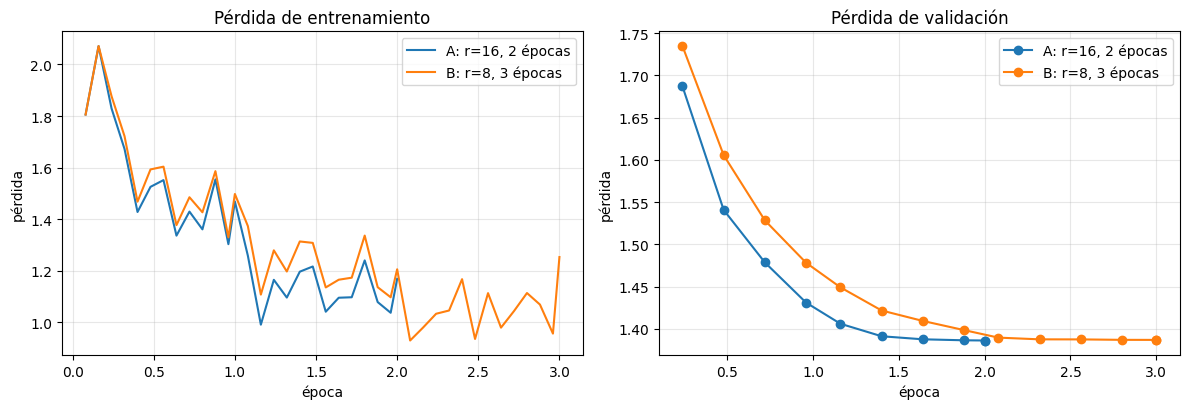

config   val inicial  val mínima  (época)  val final  train final   brecha  final vs mín  sobreajuste
A              1.687       1.386     2.00      1.386        1.095   +0.291         +0.0%  sin evidencia clara
B              1.735       1.387     3.00      1.387        1.093   +0.294         +0.0%  sin evidencia clara


In [12]:
import json, os
import matplotlib.pyplot as plt

def cargar_log(nombre):
    ruta = f"resultados/log_config_{nombre}.json"
    return json.load(open(ruta)) if os.path.exists(ruta) else None

def serie(log, clave):
    return [(e.get("epoch", 0.0), e["step"], e[clave]) for e in log if clave in e]

def diagnostico(log):
    ev, tr = serie(log, "eval_loss"), serie(log, "loss")
    entrenados = [x for x in ev if x[1] > 0]                 # excluye el paso 0 (modelo sin entrenar)
    mejor, final = min(entrenados, key=lambda x: x[2]), entrenados[-1]
    ult = [x[2] for x in tr[-3:]]
    train_final = sum(ult) / len(ult)
    sube = (final[2] - mejor[2]) / mejor[2]
    return {"val_inicial": ev[0][2], "val_min": mejor[2], "epoca_min": mejor[0], "val_final": final[2],
            "train_final": train_final, "brecha": final[2] - train_final, "sube_pct": 100 * sube,
            "sobreajuste": sube > 0.05 and tr[-1][2] < tr[len(tr) // 2][2]}

CONFIGS = {"A": "r=16, 2 épocas", "B": "r=8, 3 épocas"}      # etiquetas de la leyenda (ajústelas si cambió algo)
logs = {n: cargar_log(n) for n in CONFIGS}
faltan = [n for n, l in logs.items() if l is None]
assert not faltan, f"Falta resultados/log_config_{faltan}.json: ejecute primero esa configuración"

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for n, log in logs.items():
    tr, ev = serie(log, "loss"), serie(log, "eval_loss")
    ax[0].plot([x[0] for x in tr], [x[2] for x in tr], label=f"{n}: {CONFIGS[n]}")
    ax[1].plot([x[0] for x in ev], [x[2] for x in ev], "o-", label=f"{n}: {CONFIGS[n]}")
ax[0].set_title("Pérdida de entrenamiento"); ax[1].set_title("Pérdida de validación")
for a in ax:
    a.set_xlabel("época"); a.set_ylabel("pérdida"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig("resultados/curvas_perdida.png", dpi=150); plt.show()

print(f"{'config':<8}{'val inicial':>12}{'val mínima':>12}{'(época)':>9}{'val final':>11}{'train final':>13}{'brecha':>9}{'final vs mín':>14}  sobreajuste")
for n, log in logs.items():
    d = diagnostico(log)
    print(f"{n:<8}{d['val_inicial']:>12.3f}{d['val_min']:>12.3f}{d['epoca_min']:>9.2f}{d['val_final']:>11.3f}"
          f"{d['train_final']:>13.3f}{d['brecha']:>+9.3f}{d['sube_pct']:>+13.1f}%  {'POSIBLE' if d['sobreajuste'] else 'sin evidencia clara'}")